# 07 Đánh giá và phân tích lỗi từ dữ liệu thật

Bổ sung phần đánh giá, ca sai và giới hạn công nghiệp từ ghi chú Khánh 14/10. Dùng cùng 5.852 origin TEST và ngưỡng TRAIN đã khóa. Đây là phân tích hồi cứu, không dùng để tuning hay suy ra tiết kiệm thực.

In [1]:
from pathlib import Path
import json
import sys
ROOT = Path.cwd()
if not (ROOT / "src/steel").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
RESULT = ROOT / "reports/steel/error_analysis_2026-10-15"
verified = json.loads((RESULT / "verification.json").read_text(encoding="utf-8"))
assert verified["passed"] and verified["labels_checked_against_raw_csv"]
display(pd.Series({key: verified[key] for key in ("test_origins", "legacy_predictions_recomputed", "case_online_parity_checked", "all_future_actuals_absent_at_issue", "model_tuned")}))
print("Train lại khớp prediction:", verified["reproduction"]["passed"])

test_origins                           5852
legacy_predictions_recomputed          True
case_online_parity_checked                4
all_future_actuals_absent_at_issue     True
model_tuned                           False
dtype: object

Train lại khớp prediction: True


## Cảnh báo cũ và mới

Recall tăng nhưng precision giảm. Mốc cảnh báo 15 phút có thể chồng lấp; không đồng nhất với số sự cố hoặc số lượt kiểm tra thật.

In [2]:
display(pd.read_csv(RESULT / "alert_comparison.csv"))

,method,rows,tp,fp,fn,tn,precision,recall,f1,alert_rows,alert_origin_episodes
0,legacy_hour_buffer,5852,113,87,66,5586,0.565000,0.631285,0.596306,200,51
1,four_step_quantile,5852,155,186,24,5487,0.454545,0.865922,0.596154,341,73


## Ca thật để giải thích giới hạn

08:15 ngày 22/11 là FN của bản cũ nhưng TP của bản mới. Bản mới vẫn bỏ sót 16/11 lúc 19:30. Usage tại origin khác tổng Usage của giờ tương lai. Bốn ca được chọn để giải thích, không phải mẫu đại diện để ước lượng hiệu quả.

,issue_time,Usage_kWh,hour_total_actual_kWh,legacy_upper_kWh,legacy_case,point_sum_kWh,hour_total_p50_kWh,hour_total_calibrated_upper_kWh,current_case
0,2018-11-01 08:00:00,4.79,335.56,352.505476,TN,315.618425,255.597042,382.454413,FP
1,2018-11-16 19:30:00,59.04,393.05,240.903387,FN,208.038956,205.761921,263.849856,FN
2,2018-11-22 08:15:00,41.51,486.25,357.769848,FN,330.390433,283.590754,413.411933,TP
3,2018-11-22 09:00:00,124.49,554.01,420.049266,TP,394.642609,397.046529,444.772314,TP


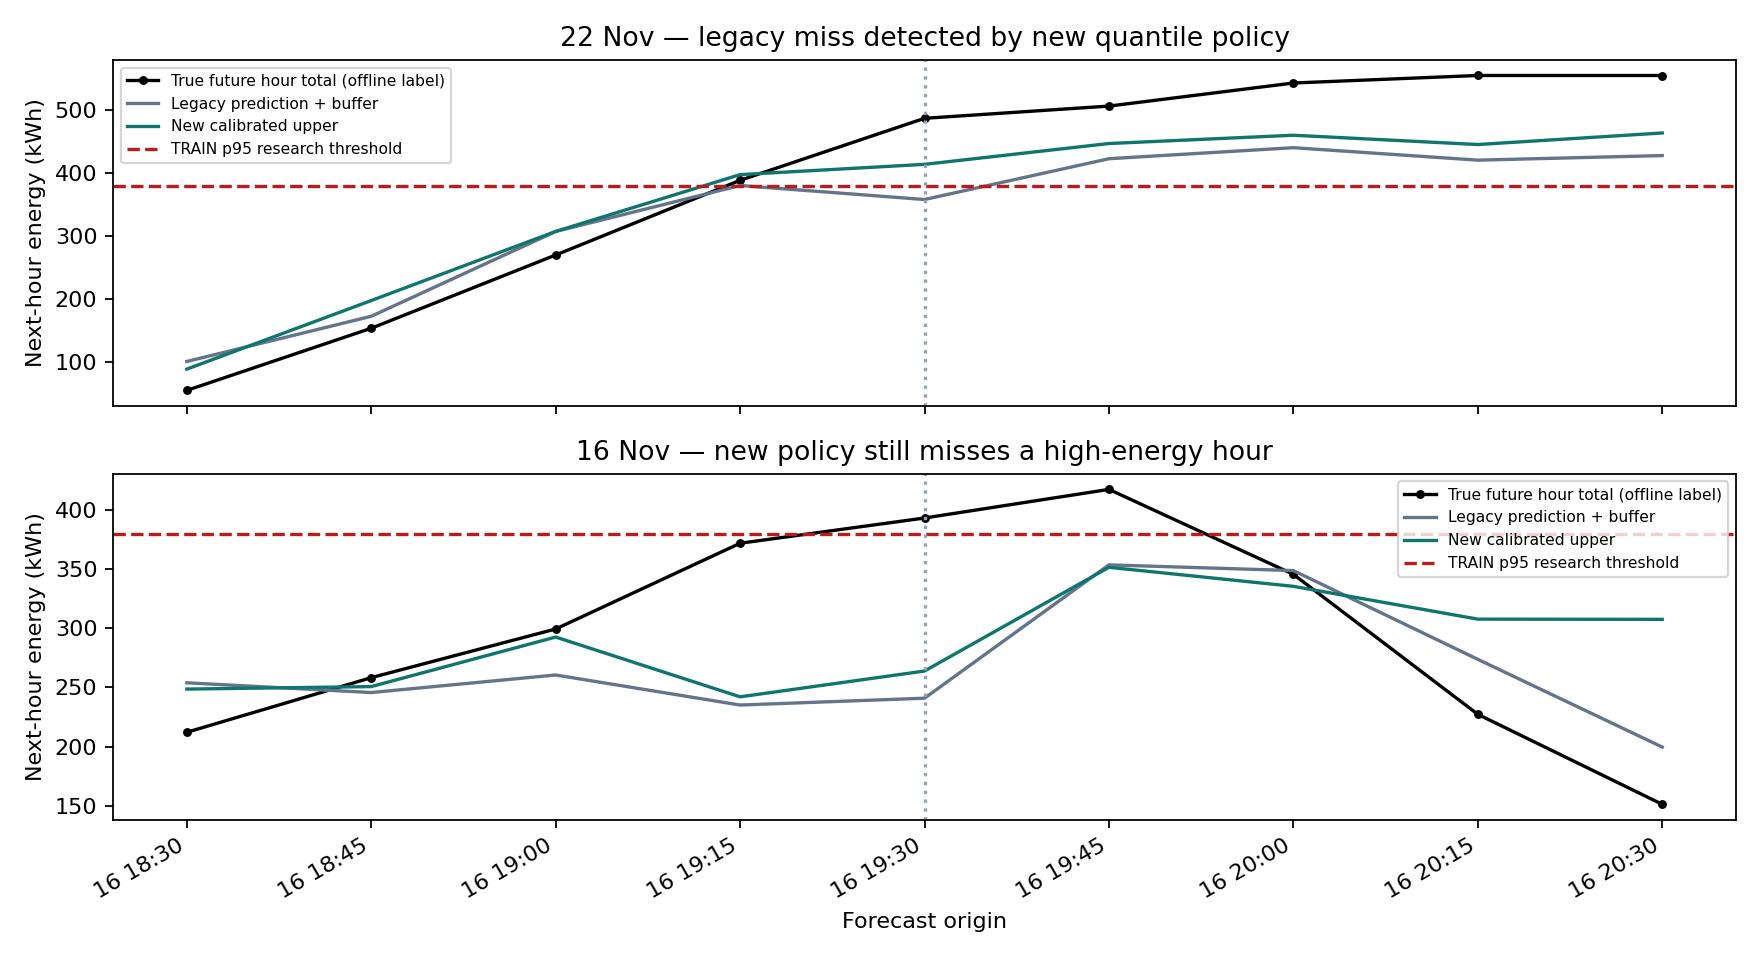

In [3]:
display(pd.read_csv(RESULT / "case_studies.csv"))
display(Image(filename=str(RESULT / "error_cases.png")))

## Độ ổn định theo thời gian

Dùng hai tháng đã đo thực, không tạo drift giả. Khác biệt theo tháng chưa xác định được nguyên nhân vận hành. Không thay model hay margin sau khi xem TEST.

In [4]:
display(pd.read_csv(RESULT / "monthly_metrics.csv"))

,month,origins,mae_per_step_kWh,mae_point_sum_kWh,coverage_after_calibration,tp,fp,fn,tn,precision,recall,f1
0,11,2880,6.090534,19.341583,0.801042,111,163,17,2589,0.405109,0.867188,0.552239
1,12,2972,3.949835,12.892054,0.766151,44,23,7,2898,0.656716,0.862745,0.745763


## Giá trị công nghiệp và phạm vi đo

AI cung cấp thông tin cho người phụ trách kiểm tra. Dataset chưa có hóa đơn, hợp đồng, lịch máy, sản lượng hoặc can thiệp để đo savings, lead time thực hoặc giảm downtime. Quyết định của người xem trong demo chưa chứng minh đã thực hiện hành động nhà máy.

In [5]:
display(pd.Series(json.loads((RESULT / "industrial_scope.json").read_text(encoding="utf-8"))))

decision                             Prioritize review of high-energy forecast orig...
true_high_origins                                                                  179
alerted_origins                                                                    341
false_positive_origins                                                             186
false_negative_origins                                                              24
unit                                 overlapping forecast origins, not physical inc...
energy_saved_kWh                                                                  None
money_saved                                                                       None
contract_power_limit_kW                                                           None
savings_measured                                                                 False
physical_event_lead_time_measured                                                False
inspection_workload_measured               

## Chạy lại

Từ gốc repo: `python -m scripts.analyze_forecast_errors --output-dir reports/steel/local_error_analysis_01`. Chọn tên mới nếu output đã có. Muốn kiểm lần train mới, dùng `--reproduction-dir` trỏ tới output của `scripts.run_probabilistic_forecast`. Notebook chỉ đọc artifact, không ghi đè model/policy.